# 🍎 Fruit Freshness Prediction

An image classification project that predicts whether a fruit is **Fresh** or **Rotten** using a trained deep learning model.

### Project Objective
The objective of this project is to develop an image-based prediction system that can classify fruit into two categories:

- 🟢 Fresh Fruit
- 🔴 Rotten Fruit

### Model
The classification model was trained using **Google Teachable Machine** and exported as a Keras model for use in Python.

### Prediction Modes
- 📁 Upload an image for prediction
- 🎥 Use a webcam for real-time prediction

---

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
from PIL import Image
from tensorflow.keras.models import load_model

import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import warnings
warnings.filterwarnings("ignore")

In [5]:
model_path = "models/fruit_freshness/keras_model.h5"
labels_path = "models/fruit_freshness/labels.txt"

In [6]:
model = load_model(model_path, compile=False)

print("Model loaded successfully! ✅")

Model loaded successfully! ✅


## Loading Class Labels

The class labels are loaded from `labels.txt` so the model's output numbers can be mapped to their corresponding fruit categories.

In [7]:
with open(labels_path, "r") as file:
    class_names = [line.strip() for line in file.readlines()]

print("Class Labels:")
for i, label in enumerate(class_names):
    print(f"{i}: {label}")

Class Labels:
0: 0 Fresh Fruit
1: 1 Rotten Fruit


In [8]:
print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)

Input shape: (None, 224, 224, 3)
Output shape: (None, 2)


## Image Preprocessing & Prediction Function

This function prepares an input image in the same format used by the trained model, performs the prediction, and returns the predicted class with its confidence score.

In [9]:
def predict_fruit(image_path):
    image = Image.open(image_path).convert("RGB")
    image = image.resize((224, 224))

    image_array = np.asarray(image, dtype=np.float32)
    image_array = (image_array / 127.5) - 1
    image_array = np.expand_dims(image_array, axis=0)

    prediction = model.predict(image_array, verbose=0)[0]

    predicted_index = np.argmax(prediction)
    predicted_label = class_names[predicted_index]
    confidence = prediction[predicted_index] * 100

    return predicted_label, confidence

## Fresh Fruit Prediction

A fresh fruit image is loaded from the testing folder and passed to the trained model for prediction. The image, predicted class, and confidence score are displayed.

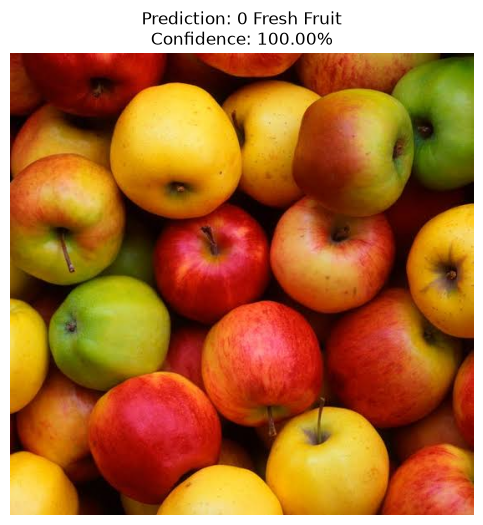

Prediction: 0 Fresh Fruit
Confidence: 100.00%


In [29]:
image_path = "Data/Testing_Fruit_Images/freshapple.jpg"

label, confidence = predict_fruit(image_path)

image = Image.open(image_path)

plt.figure(figsize=(6, 6))
plt.imshow(image)
plt.axis("off")
plt.title(f"Prediction: {label}\nConfidence: {confidence:.2f}%")
plt.show()

print(f"Prediction: {label}")
print(f"Confidence: {confidence:.2f}%")

## Rotten Fruit Prediction

A rotten fruit image is loaded from the testing folder and passed to the trained model. The predicted class and confidence score are then displayed.

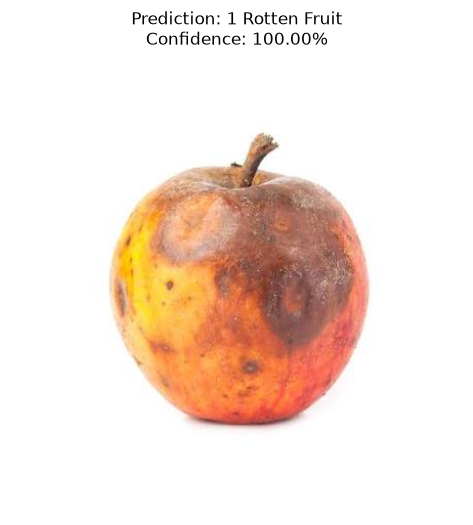

Prediction: 1 Rotten Fruit
Confidence: 100.00%


In [30]:
image_path = "Data/Testing_Fruit_Images/rottenapple.jpg"

label, confidence = predict_fruit(image_path)

image = Image.open(image_path)

plt.figure(figsize=(6, 6))
plt.imshow(image)
plt.axis("off")
plt.title(f"Prediction: {label}\nConfidence: {confidence:.2f}%")
plt.show()

print(f"Prediction: {label}")
print(f"Confidence: {confidence:.2f}%")

## Real-Time Webcam Prediction

In [31]:
cap = cv2.VideoCapture(0)

while True:
    ret, frame = cap.read()

    if not ret:
        break

    # Prepare frame for prediction
    image = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    image = cv2.resize(image, (224, 224))
    image_array = np.asarray(image, dtype=np.float32)
    image_array = (image_array / 127.5) - 1
    image_array = np.expand_dims(image_array, axis=0)

    prediction = model.predict(image_array, verbose=0)[0]

    predicted_index = np.argmax(prediction)
    label = class_names[predicted_index]
    confidence = prediction[predicted_index] * 100

    # Display prediction
    cv2.putText(
        frame,
        f"{label} ({confidence:.1f}%)",
        (20, 40),
        cv2.FONT_HERSHEY_SIMPLEX,
        1,
        (0, 255, 0),
        2
    )

    cv2.imshow("Fruit Freshness Prediction - Press Q to Exit", frame)

    if cv2.waitKey(1) & 0xFF == ord("q"):
        break

cap.release()
cv2.destroyAllWindows()

## Batch Image Testing

In [34]:
import os
import pandas as pd

test_folder = "Data/Testing_Fruit_Images"

results = []

for filename in os.listdir(test_folder):

    if filename.lower().endswith((".jpg", ".jpeg", ".png")):

        image_path = os.path.join(test_folder, filename)

        label, confidence = predict_fruit(image_path)

        # Expected label from filename
        if "fresh" in filename.lower():
            expected = "0 Fresh Fruit"
        elif "rotten" in filename.lower():
            expected = "1 Rotten Fruit"
        else:
            expected = "Unknown"

        results.append({
            "Image": filename,
            "Expected": expected,
            "Predicted": label,
            "Confidence (%)": round(confidence, 2)
        })

results_df = pd.DataFrame(results)

results_df

,Image,Expected,Predicted,Confidence (%)
0,freshapple.jpg,0 Fresh Fruit,0 Fresh Fruit,100.00
1,freshpear.jpg,0 Fresh Fruit,0 Fresh Fruit,99.67
2,freshstrawberry.jpg,0 Fresh Fruit,0 Fresh Fruit,100.00
3,rottenapple.jpg,1 Rotten Fruit,1 Rotten Fruit,100.00
4,rottengrapes.jpg,1 Rotten Fruit,1 Rotten Fruit,100.00


## Test Accuracy

In [35]:
accuracy = (results_df["Expected"] == results_df["Predicted"]).mean() * 100

print(f"Test Accuracy: {accuracy:.2f}%")

Test Accuracy: 100.00%


## Confusion Matrix

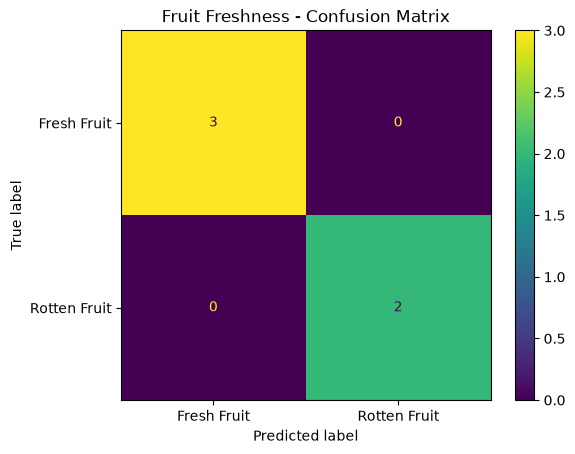

In [37]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

y_true = results_df["Expected"]
y_pred = results_df["Predicted"]

cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Fresh Fruit", "Rotten Fruit"]
)

disp.plot()
plt.title("Fruit Freshness - Confusion Matrix")
plt.show()

### Interpretation :

- The confusion matrix shows that all test images were classified correctly, with **no false positives or false negatives**. 
- This indicates **100% accuracy on the selected test images**.

---

## Model Information

- **Model Type:** Image Classification
- **Framework:** TensorFlow / Keras
- **Training Platform:** Teachable Machine
- **Input Size:** 224 × 224 × 3
- **Classes:** Fresh Fruit, Rotten Fruit
- **Prediction Modes:** Image Prediction and Real-Time Webcam Prediction

---

## Project Limitations

- Prediction performance can vary depending on image quality, lighting, background, and fruit appearance.
- The model is trained for the fruit categories represented in the training dataset.
- Confidence scores indicate the model's prediction confidence and should not be treated as absolute certainty.

---

## Conclusion

The Fruit Freshness Prediction system successfully classifies fruit images into **Fresh Fruit** and **Rotten Fruit** categories using a trained image classification model. The project demonstrates how a trained deep learning model can be integrated into Python for image-based and real-time predictions.

The model achieved **100% accuracy on the selected test images**, with all tested samples classified correctly.

---